# Agricultural Mechanization Price Analysis and Evaluation

**Data Science Capstone Project | Notebook 01 – EDA**

**Research question:** Is a quoted agricultural mechanization price within ±30% of a reasonable regional reference price?

## 1. Summary

The main price analysis contains **3.505 records** with numeric quoted and reference prices. Of these, **2.893 (82,5%)** are within ±30% of the historical reference price, while **612 (17,5%)** are outside this range. A separate investment dataset provides context, but the two datasets cannot be reliably merged.

## 2. Introduction & motivation

I want to explore whether data science can support the evaluation of agricultural mechanization prices. Farmers submit quoted prices, which can differ from regional reference prices. I will examine the quality of the data, study price deviations, and prepare a cleaned dataset for a separate machine learning notebook.

**Data Science question:** Is a quoted agricultural mechanization price within ±30% of a reasonable regional reference price?

The analysis describes historical committee decisions; it does not yet make machine learning predictions.

## 3. Data provenance

The project uses two historical Excel files provided for this Capstone and authorized for this project:

- `Mechanization_prices.xlsx` – mechanization descriptions, quoted prices and committee reference prices (6.622 original rows).
- `Mechanization.xlsx` – investment amounts, locations and production sectors (695 original rows in the analyzed version).

The exact collection dates are not documented in the supplied notebook, so no date range is assumed. The original Excel files remain unchanged. There is no verified shared identifier connecting the two datasets, so they are analyzed separately.

## 4. Data dictionary

The two tables below describe the columns of the original datasets. All amounts are in EUR unless otherwise stated.

### Mechanization prices dataset

| Column | Description |
|---|---|
| No. | Investment group number |
| Supplier | Name of the equipment supplier |
| Equipment / Item | Type of mechanization or equipment |
| Manufacturer / Brand | Manufacturer or brand of the equipment |
| Model / Specifications | Model name and technical specifications |
| Evaluation Committee Reference Price (EUR) | Reference price used for price evaluation |
| Reference Price +10% (EUR) | Reference price increased by 10% |
| Reference Price +15% (EUR) | Reference price increased by 15% |
| Reference Price +30% (EUR) | Reference price increased by 30% |
| Applicant Quoted Price (EUR) | Price quoted by the farmer |
| Final Price Proposed by Evaluation Committee (EUR) | Final price proposed after evaluation |
| Quoted Price Deviation from Reference (%) | Original price deviation, stored as a decimal fraction |

### Mechanization investments dataset

| Column | Description |
|---|---|
| Record No. | Record identification number |
| Gender | Gender of the farmer |
| Exact Description of Requested Investment | Description of the planned investment |
| Applicant Municipality | Municipality of the farmer |
| Investment Region | Region where the investment is located |
| Investment Address | Address of the investment |
| Investment Municipality | Municipality where the investment is located |
| Investment Type | Type of investment |
| Applicant Type (Individual / Legal Entity) | Whether the farmer is an individual or a legal entity |
| Primary Production Sector | Main agricultural production sector |
| Total Requested Investment (Including Ineligible Costs, with VAT) (€) | Total requested investment amount, including VAT and ineligible costs |
| Total Requested Investment (Excluding Ineligible Costs) (€) | Requested investment amount excluding ineligible costs and VAT |
| Requested Grant Support (€) | Amount of requested financial support |

## 5. Setup

I will import the libraries needed for EDA and load the two original Excel datasets.

In [1]:
# Importing libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

I will read the original files and confirm that both tables loaded correctly.

In [2]:
# Loading the two datasets

prices = pd.read_excel("Mechanization_prices.xlsx")
investments = pd.read_excel("Mechanization.xlsx")

## 6. First look

I will check the shape, first rows, data types and descriptive statistics of each dataset before making any changes.

### Mechanization prices dataset

I will check how many rows and columns are in the mechanization prices dataset.

In [3]:
prices.shape

(6622, 12)

I will preview the first ten mechanization price records.

In [4]:
prices.head(10)

,No.,Supplier,Equipment / Item,Manufacturer / Brand,Model / Specifications,Evaluation Committee Reference Price (EUR),Reference Price +10% (EUR),Reference Price +15% (EUR),Reference Price +30% (EUR),Applicant Quoted Price (EUR),Final Price Proposed by Evaluation Committee (EUR),Quoted Price Deviation from Reference (%)
0,1.0,Agromehanika doo,Potato ridger,Bomet,P475 3 rows,627.82,690.602,721.9930,816.166,595.04,595.040,-0.052212
1,1.0,Agromehanika doo,Potato planter,Bomet,S239/1 two-row,1427.63,1570.393,1641.7745,1855.919,1735.53,1570.393,0.215672
2,1.0,Agromehanika doo,Potato digger,Bomet,Z655 side-mounted,1621.54,1783.694,1864.7710,2108.002,1611.57,1611.570,-0.006148
3,1.0,Agromehanika doo,Rotary tiller,Farmers,180 cm,1443.61,1587.971,1660.1515,1876.693,1446.28,1446.280,0.001850
4,1.0,Agromehanika doo,Hay rake,FPM Deljanin,200 cm belt-type,855,940.500,983.2500,1111.500,979.33,979.330,0.145415
5,1.0,Agromehanika doo,Cab tractor,Lovol,M504,21549,23703.900,24781.3500,28013.700,23347.93,23347.930,0.083481
6,2.0,Agromehanika doo,Rotary tiller,Farmers,160 cm,1232.21,1355.431,1417.0415,1601.873,1363.63,1355.431,0.106654
7,2.0,Agromehanika doo,Trailer with side extensions,Fermak,4t,4821.4,5303.540,5544.6100,6267.820,4754.54,4754.540,-0.013867
8,2.0,Agromehanika doo,Rotary mower,FPM,DK130/31N disc-type,3313.13,3644.443,3810.0995,4307.069,2943.67,2943.670,-0.111514
9,2.0,Agromehanika doo,Cab tractor,Lovol,M754,25878.5,28466.350,29760.2750,33642.050,29520.66,28466.350,0.140741


I will check column types and non-null values to identify possible cleaning needs.

In [5]:
prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6622 entries, 0 to 6621
Data columns (total 12 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   No.                                                 3971 non-null   float64
 1   Supplier                                            3970 non-null   object 
 2   Equipment / Item                                    3971 non-null   object 
 3   Manufacturer / Brand                                3321 non-null   object 
 4   Model / Specifications                              3930 non-null   object 
 5   Evaluation Committee Reference Price (EUR)          3557 non-null   object 
 6   Reference Price +10% (EUR)                          6573 non-null   float64
 7   Reference Price +15% (EUR)                          4281 non-null   float64
 8   Reference Price +30% (EUR)                          4479 non-null   float64
 9

I will review basic statistics for the numeric price columns.

In [6]:
prices.describe()

,No.,Reference Price +10% (EUR),Reference Price +15% (EUR),Reference Price +30% (EUR),Applicant Quoted Price (EUR),Final Price Proposed by Evaluation Committee (EUR),Quoted Price Deviation from Reference (%)
count,3971.000000,6573.00000,4281.000000,4479.000000,3970.000000,3649.000000,3515.000000
mean,280.504155,4716.00845,7569.136070,8177.262839,8873.767045,7939.293222,0.112411
std,159.927561,11944.65155,14814.589528,16467.083318,15094.418259,13979.518862,0.252820
min,1.000000,0.00000,0.000000,0.000000,1.810000,0.000000,-0.715481
25%,139.500000,0.00000,200.226500,140.023000,1293.880000,996.182000,-0.016764
50%,278.000000,145.51900,1955.000000,2096.952000,2979.340000,2600.000000,0.073977
75%,424.000000,3520.00000,6984.709000,7708.090000,9650.000000,7735.189000,0.193142
max,552.000000,181091.02000,189322.430000,214016.660000,185000.000000,170256.900000,3.996193


### Initial findings – mechanization prices

The dataset contains 6.622 rows and 12 columns. It includes information about mechanization types, manufacturers, models, farmers' quoted prices, and reference prices. Some columns contain missing values, and the reference price column is stored as an object instead of a numeric data type. These issues will be investigated during data cleaning.

### Mechanization investments dataset

I will check the size of the investment dataset.

In [7]:
investments.shape

(695, 13)

I will preview the investment records to understand the available information.

In [8]:
investments.head(10)

,Record No.,Gender,Exact Description of Requested Investment,Applicant Municipality,Investment Region,Investment Address,Investment Municipality,Investment Type,Applicant Type (Individual / Legal Entity),Primary Production Sector,"Total Requested Investment (Including Ineligible Costs, with VAT) (€)",Total Requested Investment (Excluding Ineligible Costs) (€),Requested Grant Support (€)
0,1,M,Establishment of an orchard and purchase of ma...,Nikšić,Northern,Mljetičak (no street number),Šavnik,Establishment of an orchard and purchase of ma...,Individual,"Fruit, vegetable and field crop production",31447.20,28309.21,21231.9075
1,2,M,Purchase of agricultural machinery,Bijelo Polje,Northern,Pavino Polje,Bijelo Polje,Purchase of machinery,Individual,"Fruit, vegetable and field crop production",56792.00,46935.47,30508.0555
2,3,F,Technological improvement of an olive grove – ...,Podgorica,Coastal,Vranovići (no street number),Kotor,Purchase of machinery,Legal entity,Olive production,491421.17,406132.90,284293.0300
3,4,M,Purchase of specialised machinery for field cr...,Berane,Northern,Village Goražde-Polica,Berane,Purchase of machinery,Individual,"Fruit, vegetable and field crop production",35956.00,29715.70,19315.2050
4,5,M,Purchase of tractor and potato harvester,Pljevlja,Northern,Village Kruševo,Pljevlja,Purchase of machinery,Individual,"Fruit, vegetable and field crop production",23222.15,19191.85,12474.7025
5,6,M,Purchase of machinery,Bijelo Polje,Northern,Pape - Tomaševo,Bijelo Polje,Purchase of machinery,Individual,Milk production,76822.85,63594.09,41336.1585
6,7,M,Purchase of agricultural machinery,Nikšić,Central,Ivanje,Nikšić,Purchase of machinery,Individual,Meat production,46282.50,38250.00,24862.5000
7,8,M,Purchase of agricultural machinery,Bijelo Polje,Northern,Barice (no street number),Bijelo Polje,Purchase of machinery,Individual,"Fruit, vegetable and field crop production",56331.55,46555.00,30260.7500
8,9,M,Purchase of agricultural machinery,Kolašin,Northern,Smailagića polje (no street number),Kolašin,Purchase of machinery,Individual,"Fruit, vegetable and field crop production",55355.10,45748.02,34311.0150
9,10,M,Purchase of agricultural machinery,Tuzi,Central,Kuće Rakića,Tuzi,Purchase of machinery,Individual,Viticulture,72127.02,59609.11,41726.3770


I will inspect the investment column types and missing values.

In [9]:
investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 695 entries, 0 to 694
Data columns (total 13 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   Record No.                                                             695 non-null    int64  
 1   Gender                                                                 695 non-null    object 
 2   Exact Description of Requested Investment                              692 non-null    object 
 3   Applicant Municipality                                                 689 non-null    object 
 4   Investment Region                                                      693 non-null    object 
 5   Investment Address                                                     693 non-null    object 
 6   Investment Municipality                                                695 non-null    obj

I will review the numeric investment statistics.

In [10]:
investments.describe()

,Record No.,"Total Requested Investment (Including Ineligible Costs, with VAT) (€)",Total Requested Investment (Excluding Ineligible Costs) (€),Requested Grant Support (€)
count,695.000000,6.950000e+02,6.950000e+02,6.950000e+02
mean,348.000000,1.415855e+05,1.170179e+05,8.085894e+04
std,200.773504,4.212081e+05,3.481047e+05,2.461787e+05
min,1.000000,1.908702e+03,1.577440e+03,1.025336e+03
25%,174.500000,4.345546e+04,3.591360e+04,2.342938e+04
50%,348.000000,6.399085e+04,5.288500e+04,3.568228e+04
75%,521.500000,1.143083e+05,9.446967e+04,6.339788e+04
max,695.000000,9.217300e+06,7.617603e+06,4.951442e+06


### Initial Findings – Mechanization

The dataset contains 695 rows and 13 columns. It includes information about investment amounts, production sectors, municipalities, and application details. Some columns contain missing values, while the investment amount columns are stored as numeric values.

## 7. Data quality audit

I will check missing values, duplicates, numeric price fields and unusually large investment amounts. I will explain the cleaning decisions and keep the original datasets unchanged.

I will calculate the percentage of missing values in each price column.

In [11]:
# Percentage of missing values in mechanization prices

(prices.isnull().mean() * 100).round(2)

,0
No.,40.03
Supplier,40.05
Equipment / Item,40.03
Manufacturer / Brand,49.85
Model / Specifications,40.65
Evaluation Committee Reference Price (EUR),46.29
Reference Price +10% (EUR),0.74
Reference Price +15% (EUR),35.35
Reference Price +30% (EUR),32.36
Applicant Quoted Price (EUR),40.05


I will check whether the original prices dataset contains exact duplicate rows.

In [12]:
# Checking duplicate rows
prices.duplicated().sum()

np.int64(2658)

### Missing values and duplicates

Several columns have around 40% missing values, while the Manufacturer / Brand column has almost 50%. The Equipment / Item column has 40,03% missing values. This may be related to the structure of the original Excel file.

The dataset also contains duplicate records that will be reviewed during data cleaning.

I will plot missing-value percentages to see which columns need attention.

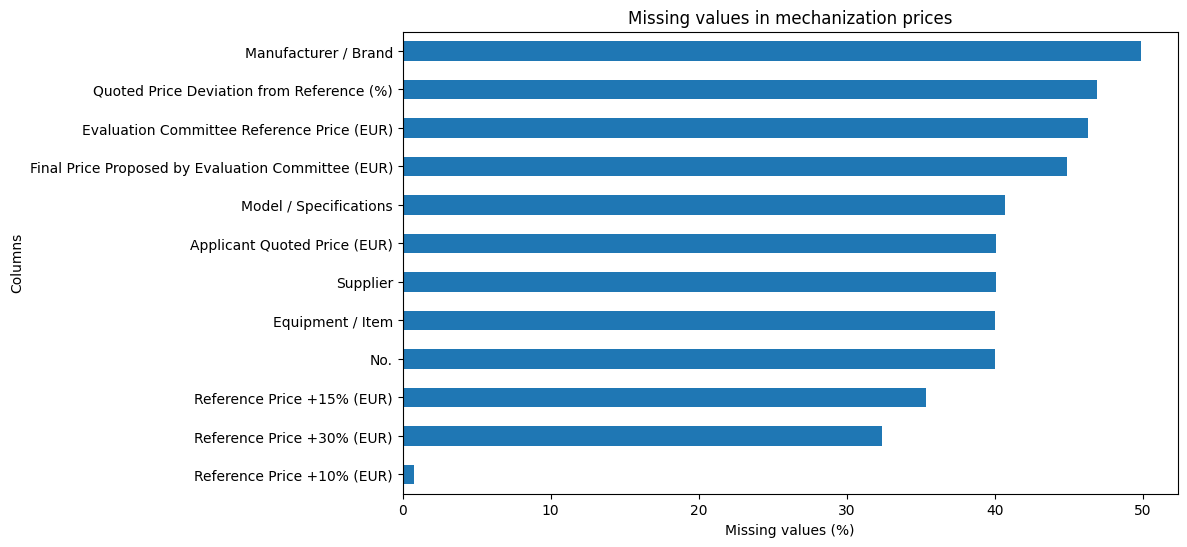

In [13]:
# Percentage of missing values by column

missing = prices.isnull().mean() * 100

plt.figure(figsize=(10, 6))
missing.sort_values().plot(kind="barh")

plt.title("Missing values in mechanization prices")
plt.xlabel("Missing values (%)")
plt.ylabel("Columns")
plt.show()

The chart shows missing values in the original Mechanization prices dataset.

Several columns have a large number of missing values. However, many of these may come from rows without complete mechanization information.

I will investigate these rows during data cleaning before deciding which records to keep.

I will calculate missing-value percentages in the investment dataset.

In [14]:
# Percentage of missing values in investments

(investments.isnull().mean() * 100).round(2)

,0
Record No.,0.00
Gender,0.00
Exact Description of Requested Investment,0.43
Applicant Municipality,0.86
Investment Region,0.29
Investment Address,0.29
Investment Municipality,0.00
Investment Type,0.14
Applicant Type (Individual / Legal Entity),0.00
Primary Production Sector,1.44


I will check for duplicate investment rows.

In [15]:
# Checking duplicate rows
investments.duplicated().sum()

np.int64(0)

### Missing values and duplicates

The investments dataset has very few missing values, mainly in descriptive columns.

The highest percentage is in Primary Production Sector (1,44%), followed by Applicant Municipality (0,86%).

All three financial columns have no missing values.

No duplicate rows were found.

I will plot the missing-value percentages in the investment dataset.

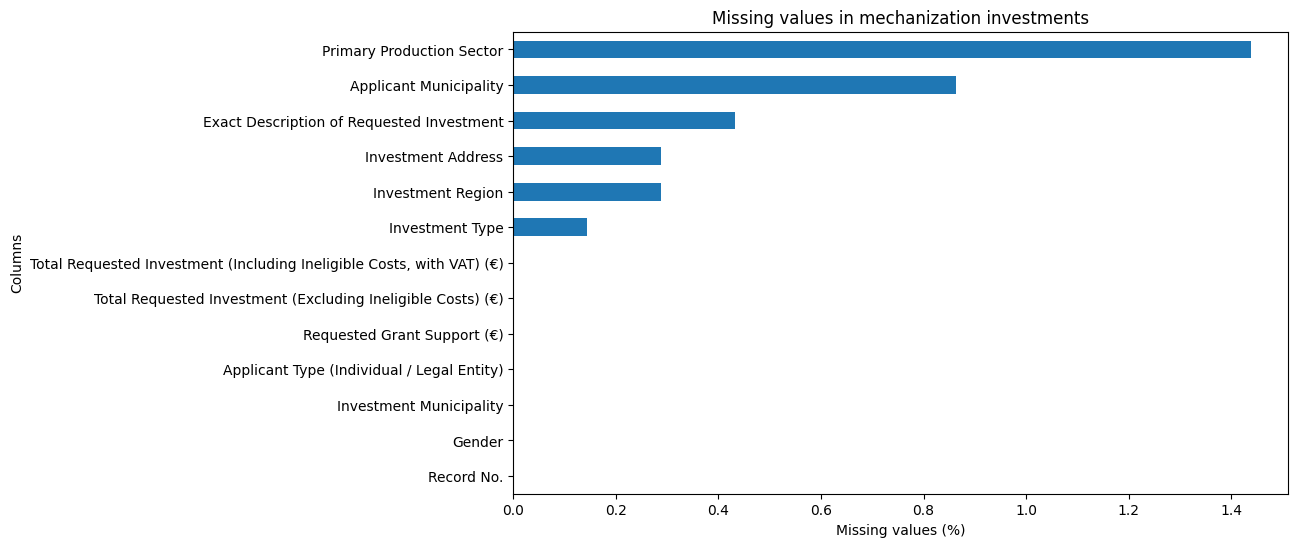

In [16]:
# Percentage of missing values by column

missing = investments.isnull().mean() * 100

plt.figure(figsize=(10, 6))
missing.sort_values().plot(kind="barh")

plt.title("Missing values in mechanization investments")
plt.xlabel("Missing values (%)")
plt.ylabel("Columns")
plt.show()

The chart shows that the Mechanization dataset has very few missing values.

Primary Production Sector has the highest percentage (1,44%), followed by Applicant Municipality (0,86%).

All three financial columns have no missing values.

In this section, I will clean the mechanization prices dataset by checking incomplete records, missing values, and data types.

The goal is to prepare the data for further analysis and machine learning.

I will keep rows with an investment number, equipment description and quoted price. This removes records that cannot support the price analysis.

In [17]:
# I'm keeping records with basic mechanization and price information

prices_clean = prices.dropna(subset=[
        "No.",
        "Equipment / Item",
        "Applicant Quoted Price (EUR)"]).copy()

prices_clean.shape

(3970, 12)

I will preview the filtered dataset.

In [18]:
# Preview of the filtered dataset

prices_clean.head(10)

,No.,Supplier,Equipment / Item,Manufacturer / Brand,Model / Specifications,Evaluation Committee Reference Price (EUR),Reference Price +10% (EUR),Reference Price +15% (EUR),Reference Price +30% (EUR),Applicant Quoted Price (EUR),Final Price Proposed by Evaluation Committee (EUR),Quoted Price Deviation from Reference (%)
0,1.0,Agromehanika doo,Potato ridger,Bomet,P475 3 rows,627.82,690.602,721.9930,816.166,595.04,595.040,-0.052212
1,1.0,Agromehanika doo,Potato planter,Bomet,S239/1 two-row,1427.63,1570.393,1641.7745,1855.919,1735.53,1570.393,0.215672
2,1.0,Agromehanika doo,Potato digger,Bomet,Z655 side-mounted,1621.54,1783.694,1864.7710,2108.002,1611.57,1611.570,-0.006148
3,1.0,Agromehanika doo,Rotary tiller,Farmers,180 cm,1443.61,1587.971,1660.1515,1876.693,1446.28,1446.280,0.001850
4,1.0,Agromehanika doo,Hay rake,FPM Deljanin,200 cm belt-type,855,940.500,983.2500,1111.500,979.33,979.330,0.145415
5,1.0,Agromehanika doo,Cab tractor,Lovol,M504,21549,23703.900,24781.3500,28013.700,23347.93,23347.930,0.083481
6,2.0,Agromehanika doo,Rotary tiller,Farmers,160 cm,1232.21,1355.431,1417.0415,1601.873,1363.63,1355.431,0.106654
7,2.0,Agromehanika doo,Trailer with side extensions,Fermak,4t,4821.4,5303.540,5544.6100,6267.820,4754.54,4754.540,-0.013867
8,2.0,Agromehanika doo,Rotary mower,FPM,DK130/31N disc-type,3313.13,3644.443,3810.0995,4307.069,2943.67,2943.670,-0.111514
9,2.0,Agromehanika doo,Cab tractor,Lovol,M754,25878.5,28466.350,29760.2750,33642.050,29520.66,28466.350,0.140741


I will check data types and non-null values.

In [19]:
# Checking data types and non-null values

prices_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3970 entries, 0 to 3970
Data columns (total 12 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   No.                                                 3970 non-null   float64
 1   Supplier                                            3969 non-null   object 
 2   Equipment / Item                                    3970 non-null   object 
 3   Manufacturer / Brand                                3320 non-null   object 
 4   Model / Specifications                              3926 non-null   object 
 5   Evaluation Committee Reference Price (EUR)          3557 non-null   object 
 6   Reference Price +10% (EUR)                          3927 non-null   float64
 7   Reference Price +15% (EUR)                          3925 non-null   float64
 8   Reference Price +30% (EUR)                          3923 non-null   float64
 9   Ap

### Filtering incomplete records

I filtered the dataset to keep records with an investment number, equipment name, and farmers' quoted price.

The filtered dataset contains 3.970 rows and 12 columns.

I will continue checking missing values and data types before using these records for further analysis.

### Checking reference price values

The reference price column is stored as an object instead of a numeric data type. I will investigate its values before converting it.

I will identify text notes stored in the reference price column before converting that column to numbers.

In [20]:
# Find non-numeric reference price values

col = "Evaluation Committee Reference Price (EUR)"

numeric_prices = pd.to_numeric(prices_clean[col], errors="coerce")

prices_clean.loc[
numeric_prices.isnull() & prices_clean[col].notnull(),col].value_counts()

,count
Evaluation Committee Reference Price (EUR),
Reasonable price,13
Reasonable price – comparable model,11
REALNA,5
realnA,3
Reasonable price – comparable item,2
Comparable model – reasonable price,1
Unreasonable price,1
Price correction,1


### Reference price findings

I found 37 non-numeric values in the reference price column. These values are text notes from the Evaluation Committee, such as "Reasonable price" and "Price correction". I will keep these notes in a separate column and convert the reference prices to numeric values.

I will preserve evaluation notes in a separate column and convert valid reference prices to numeric values.

In [21]:
# Separating evaluation notes from numeric prices

prices_clean["Evaluation Note"] = prices_clean[col].where(
    numeric_prices.isnull() & prices_clean[col].notnull())

prices_clean[col] = numeric_prices

I will check the cleaned reference price column.

In [22]:
# Checking the cleaned reference price column

prices_clean[[col, "Evaluation Note"]].info()

<class 'pandas.core.frame.DataFrame'>
Index: 3970 entries, 0 to 3970
Data columns (total 2 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Evaluation Committee Reference Price (EUR)  3520 non-null   float64
 1   Evaluation Note                             37 non-null     object 
dtypes: float64(1), object(1)
memory usage: 93.0+ KB


### Cleaning reference prices – results

The reference price column has been converted to a numeric data type. There are 3.520 numeric reference prices and 37 evaluation notes, which were saved in a separate column. A total of 450 records have no numeric reference price. These records will be reviewed before preparing the data for machine learning.

I will check records with missing reference prices.

In [23]:
# Checking records with missing reference prices

missing_reference = prices_clean[
    prices_clean[col].isnull()]

missing_reference[
    ["Equipment / Item",
     "Manufacturer / Brand",
     "Model / Specifications",
     "Applicant Quoted Price (EUR)",
     "Evaluation Note"]].head(10)

,Equipment / Item,Manufacturer / Brand,Model / Specifications,Applicant Quoted Price (EUR),Evaluation Note
38,Hay rake,Sip,star 300 balerina,4554.13,Reasonable price – comparable model
84,Hay rake,NaN,star 300 balerina,4554.13,Reasonable price – comparable model
253,Cab tractor,Valtra,A 105 MH4,89200.00,Reasonable price – comparable model
401,Seedbed cultivator,NaN,OK 2 + 3 nagrtača,2208.83,Reasonable price – comparable model
497,Hay rake,NaN,star 300 balerina,4554.13,Comparable model – reasonable price
620,Tracked vehicle,Topone,for zaštitu voća samohodna daljinsko upravljan...,4847.11,Reasonable price – comparable model
622,Tractor with loader,Topone,TL 1500,24603.33,Reasonable price – comparable model
739,Seedbed cultivator,NaN,OK 2 + 3 nagrtača,2208.83,Reasonable price – comparable model
813,Tractor tire chains,Veriga,Star Extreme,5500.00,Unreasonable price
1212,Cab tractor,Case IH,Maxxum 135,153000.00,NaN


### Missing reference prices – findings

Some records have evaluation notes instead of numeric reference prices, while others have no reference price or note.

Records without numeric reference prices will not be used in the main price analysis.

I will check missing reference prices.

In [24]:
# Checking missing reference prices

missing_reference["Evaluation Note"].notnull().value_counts()

,count
Evaluation Note,
False,413
True,37


### Missing reference price summary

Out of 450 records without numeric reference prices, 37 contain evaluation notes and 413 have no reference information. These records will not be used to train a model that predicts reference prices, but they will remain available for further analysis.

I will check duplicate rows in the filtered dataset.

In [25]:
# Checking duplicate rows in the filtered dataset

prices_clean.duplicated().sum()

np.int64(16)

Now I will show all duplicate records.

In [26]:
# Showing all duplicate records

prices_clean[prices_clean.duplicated(keep=False)].sort_values("No.")

,No.,Supplier,Equipment / Item,Manufacturer / Brand,Model / Specifications,Evaluation Committee Reference Price (EUR),Reference Price +10% (EUR),Reference Price +15% (EUR),Reference Price +30% (EUR),Applicant Quoted Price (EUR),Final Price Proposed by Evaluation Committee (EUR),Quoted Price Deviation from Reference (%),Evaluation Note
148,22.0,Agro auto doo,PTO shaft,NaN,c line 06,201.64,221.804,231.8860,262.132,195.53,195.53,-0.030302,NaN
149,22.0,Agro auto doo,PTO shaft,NaN,c line 06,201.64,221.804,231.8860,262.132,195.53,195.53,-0.030302,NaN
237,37.0,Agro auto doo,PTO shaft,NaN,01 br c universal,78.74,86.614,90.5510,102.362,77.42,77.42,-0.016764,NaN
238,37.0,Agro auto doo,PTO shaft,NaN,01 br c universal,78.74,86.614,90.5510,102.362,77.42,77.42,-0.016764,NaN
239,37.0,Agro auto doo,PTO shaft,NaN,01 br c universal,78.74,86.614,90.5510,102.362,77.42,77.42,-0.016764,NaN
545,81.0,Agro auto doo,PTO shaft,NaN,c line 04 ST,171.57,188.727,197.3055,223.041,169.02,169.02,-0.014863,NaN
546,81.0,Agro auto doo,PTO shaft,NaN,c line 04 ST,171.57,188.727,197.3055,223.041,169.02,169.02,-0.014863,NaN
762,111.0,Agro auto doo,PTO shaft,NaN,01 br c universal,78.74,86.614,90.5510,102.362,77.42,77.42,-0.016764,NaN
763,111.0,Agro auto doo,PTO shaft,NaN,01 br c universal,78.74,86.614,90.5510,102.362,77.42,77.42,-0.016764,NaN
1016,140.0,Agro auto doo,PTO shaft,NaN,01 br c universal,78.74,86.614,90.5510,102.362,77.42,77.42,-0.016764,NaN


I will count identical records before removing duplicates, so their previous frequency is preserved.

In [27]:
# Counting repeated records before removing duplicates
columns = prices_clean.columns.tolist()

prices_clean["Record Frequency"] = (
prices_clean.groupby(columns, dropna=False)["No."].transform("size"))

I will remove exact duplicates and check the new dataset size.

In [28]:
# Removing exact duplicates
prices_clean = prices_clean.drop_duplicates(subset=columns).copy()

prices_clean.shape

(3954, 14)

I will check frequency of repeated records.

In [29]:
# Checking frequency of repeated records

prices_clean["Record Frequency"].value_counts().sort_index()

,count
Record Frequency,
1,3941
2,10
3,3


Now I will check the results.

In [30]:
prices_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3954 entries, 0 to 3970
Data columns (total 14 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   No.                                                 3954 non-null   float64
 1   Supplier                                            3953 non-null   object 
 2   Equipment / Item                                    3954 non-null   object 
 3   Manufacturer / Brand                                3319 non-null   object 
 4   Model / Specifications                              3910 non-null   object 
 5   Evaluation Committee Reference Price (EUR)          3505 non-null   float64
 6   Reference Price +10% (EUR)                          3911 non-null   float64
 7   Reference Price +15% (EUR)                          3909 non-null   float64
 8   Reference Price +30% (EUR)                          3907 non-null   float64
 9   Ap

### Duplicate records – findings

I found 16 duplicate rows, representing 13 repeated records. Before removing the duplicates, I created a new column called `Record Frequency` to keep track of how often each identical record appeared.

After removing duplicates, the dataset contains 3.954 records, while the frequency information is preserved.

I will review unique equipment names.

In [31]:
# Reviewing unique equipment names

sorted(prices_clean["Equipment / Item"].dropna().unique())

['Agricultural produce transport vehicle',
 'Air-blast sprayer',
 'Attachments',
 'Automatic calf feeder',
 'Automatic milk pipeline cleaning system',
 'Backhoe attachment',
 'Backpack sprayer',
 'Bale trailer',
 'Bale wrapper',
 'Baler',
 'Ballast weight',
 'Barn manure scraper channel',
 'Battery-powered pruning shears',
 'Beehive container',
 'Big-bag lifting attachment',
 'Boom arm attachment',
 'Boom mower',
 'Brushcutter',
 'Bucket',
 'Bulk material bucket',
 'Cab tractor',
 'Cattle drinking trough',
 'Cattle stall barriers',
 'Chisel plow / ripper',
 'Cleaning and leveling blade',
 'Combined machine',
 'Conveyor',
 'Conveyor belt',
 'Corn harvester',
 'Cow cubicles',
 'Cutting bar',
 'Disc harrow',
 'Electric cultivator',
 'Electric fence energizer',
 'Electric loader',
 'Electric pruner…',
 'Feed barrier',
 'Feed mixer wagon',
 'Flatbed transport trailer',
 'Floor vacuum cleaner',
 'Forage harvester',
 'Forklift',
 'Front PTO output',
 'Front linkage and front PTO',
 'Front lin

I will review unclear equipment descriptions.

In [32]:
# Reviewing unclear equipment descriptions

unclear_names = [
    "Front linkage and front PTO (hydraulics and PTO?; source text unclear)",
    "Electric pruner…",
    "Training",
    "Transport",
    "Attachments"]

prices_clean[
    prices_clean["Equipment / Item"].isin(unclear_names)][
    ["Equipment / Item", "Manufacturer / Brand", "Model / Specifications"]]

,Equipment / Item,Manufacturer / Brand,Model / Specifications
3817,Front linkage and front PTO (hydraulics and PT...,NaN,NaN
3864,Attachments,NaN,NaN
3870,Electric pruner…,Pellenc,T220-300
3871,Transport,NaN,NaN
3872,Training,NaN,NaN


I will correct an unclear equipment name.

In [33]:
# Correcting unclear equipment name

prices_clean["Equipment / Item"] = prices_clean["Equipment / Item"].replace({
    "Front linkage and front PTO (hydraulics and PTO?; source text unclear)": "Front linkage and front PTO"})

### Equipment names – findings

I reviewed the equipment names and compared unclear descriptions with the original dataset. Most names were already translated into English.

One unclear description was corrected, while the remaining names were kept unchanged.

I will check zero and negative prices.

In [34]:
# Checking zero and negative prices

price_columns = [
    "Applicant Quoted Price (EUR)",
    "Evaluation Committee Reference Price (EUR)"]

(prices_clean[price_columns] <= 0).sum()

,0
Applicant Quoted Price (EUR),0
Evaluation Committee Reference Price (EUR),0


### Price validation

No zero or negative values were found in the quoted or numeric reference prices. Missing reference prices will be handled separately.

I will select records with both quoted and numeric reference prices for the main analysis.

In [35]:
# Keeping records with both quoted and reference prices

prices_analysis = prices_clean.dropna(subset=[
        "Applicant Quoted Price (EUR)",
        "Evaluation Committee Reference Price (EUR)"]).copy()

prices_analysis.shape

(3505, 14)

### Preparing data for price analysis

I created a separate dataset containing 3.505 records with both quoted and reference prices. These records will be used to analyze price differences and prepare the machine learning model.

I will calculate the percentage difference between the quoted and reference prices.

In [36]:
# Calculating price deviation (%)

prices_analysis["Price Deviation (%)"] = (
    (prices_analysis["Applicant Quoted Price (EUR)"] -
     prices_analysis["Evaluation Committee Reference Price (EUR)"])
    / prices_analysis["Evaluation Committee Reference Price (EUR)"]) * 100

prices_analysis[
    ["Applicant Quoted Price (EUR)",
     "Evaluation Committee Reference Price (EUR)",
     "Price Deviation (%)"]].head(10)

,Applicant Quoted Price (EUR),Evaluation Committee Reference Price (EUR),Price Deviation (%)
0,595.04,627.82,-5.221242
1,1735.53,1427.63,21.567213
2,1611.57,1621.54,-0.614848
3,1446.28,1443.61,0.184953
4,979.33,855.00,14.541520
5,23347.93,21549.00,8.348090
6,1363.63,1232.21,10.665390
7,4754.54,4821.40,-1.386734
8,2943.67,3313.13,-11.151389
9,29520.66,25878.50,14.074077


I will convert the original deviation values from fractions to percentages.

In [37]:
# Converting original deviations to percentages
prices_analysis["Original Deviation (%)"] = (
    prices_analysis["Quoted Price Deviation from Reference (%)"] * 100)

Now I'm comparing calculated and original deviations.

In [38]:
# Now I' comparing calculated and original deviations
prices_analysis[["Price Deviation (%)", "Original Deviation (%)"]].head(10)

,Price Deviation (%),Original Deviation (%)
0,-5.221242,-5.221242
1,21.567213,21.567213
2,-0.614848,-0.614848
3,0.184953,0.184953
4,14.541520,14.541520
5,8.348090,8.348090
6,10.665390,10.665390
7,-1.386734,-1.386734
8,-11.151389,-11.151389
9,14.074077,14.074077


I will compare both deviation calculations to validate the result.

In [39]:
# Checking differences between calculated and original deviations

difference = (
    prices_analysis["Price Deviation (%)"] -
    prices_analysis["Original Deviation (%)"]).abs()

difference.describe()

,0
count,3.500000e+03
mean,1.770522e-14
std,2.921710e-14
min,0.000000e+00
25%,3.552714e-15
50%,9.048318e-15
75%,2.486900e-14
max,5.115908e-13


### Price deviation validation

The calculated and original price deviations match almost exactly. Small differences are caused by floating-point precision. Five records have missing original deviation values, so 3.500 records were compared.

### Checking unusual investment amounts

The two largest requested investments in the original analysis are **7.617.603,00 EUR** (Record No. 678) and **4.035.392,00 EUR** (Record No. 677). I will inspect and exclude these unverified records only from the cleaned investment analysis.

I will inspect the two unusually high investment amounts in the original investment data.

In [40]:
# Review unusual investment amounts identified during EDA
investments_clean = investments.copy()

investments_clean[
    investments_clean["Record No."].isin([677, 678])]

,Record No.,Gender,Exact Description of Requested Investment,Applicant Municipality,Investment Region,Investment Address,Investment Municipality,Investment Type,Applicant Type (Individual / Legal Entity),Primary Production Sector,"Total Requested Investment (Including Ineligible Costs, with VAT) (€)",Total Requested Investment (Excluding Ineligible Costs) (€),Requested Grant Support (€)
676,677,M,Purchase of specialised machinery (tractor wit...,Bijelo Polje,Northern,Voja Lješnjaka br. 78,Bijelo Polje,Purchase of machinery,Individual,"Fruit, vegetable and field crop production",4882824.32,4035392.0,2623004.80
677,678,M,Purchase of machinery,Bijelo Polje,Northern,Radojeva glava-Bistrica,Bijelo Polje,Purchase of machinery,Individual,Milk production,9217299.63,7617603.0,4951441.95


Two unusually high investment amounts (Record No. 677 and 678) were also found in the original Excel file. Since the correct values could not be confirmed, I will exclude these two records from the investment amount analysis. The original dataset will remain unchanged.

I will exclude the two unverified amounts from the cleaned investment table without changing the raw data.

In [41]:
# Excluding two unverified investment amounts
investments_clean = investments_clean[
    ~investments_clean["Record No."].isin([677, 678])].copy()

investments_clean.shape

(693, 13)

## 8. Univariate exploration

I will now explore one variable at a time: production sector, investment amount, reference price and price deviation. The plots help show the most common values and unusual distributions.

### Investments by production sector

I will plot how many investments belong to each production sector.

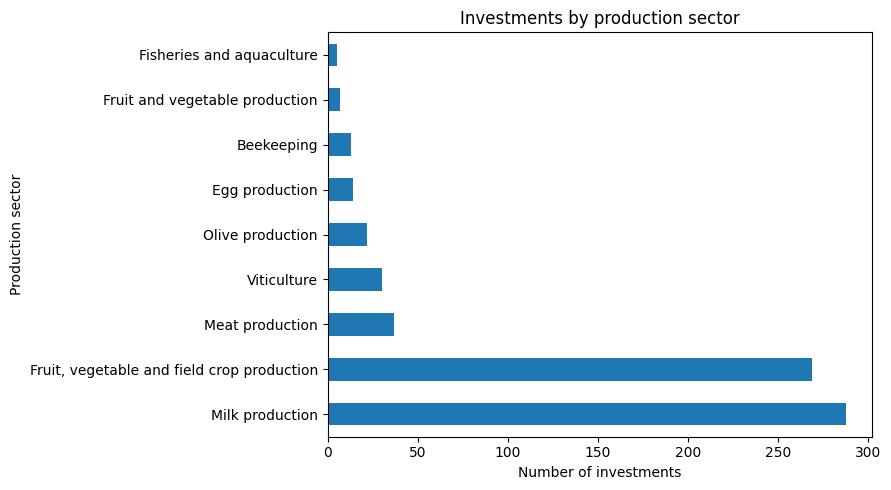

In [42]:
# Number of investments by production sector

plt.figure(figsize=(9, 5))

investments["Primary Production Sector"].value_counts().plot(kind="barh")

plt.title("Investments by production sector")
plt.xlabel("Number of investments")
plt.ylabel("Production sector")

plt.tight_layout()
plt.show()

The chart shows that most investments are related to milk production and fruit, vegetable, and field crop production. Other sectors have significantly fewer investments.

I will plot the original investment amount distribution to identify unusually large values.

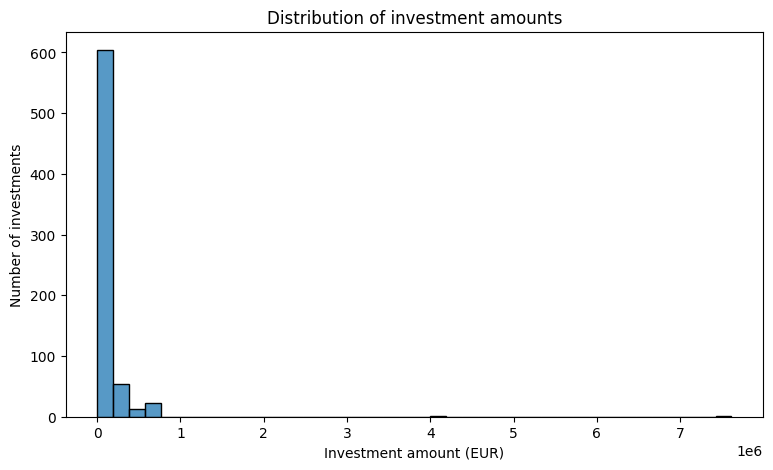

In [43]:
# Distribution of investment amounts

plt.figure(figsize=(9, 5))

sns.histplot(
    data=investments,
    x="Total Requested Investment (Excluding Ineligible Costs) (€)", bins=40)

plt.title("Distribution of investment amounts")
plt.xlabel("Investment amount (EUR)")
plt.ylabel("Number of investments")

plt.show()

### Investment Amount Distribution – Findings

Most investments have relatively low values, while a small number have much higher amounts. The distribution is strongly right-skewed, so I will check the largest investment values.

I will plot the distribution of quoted-price deviations.

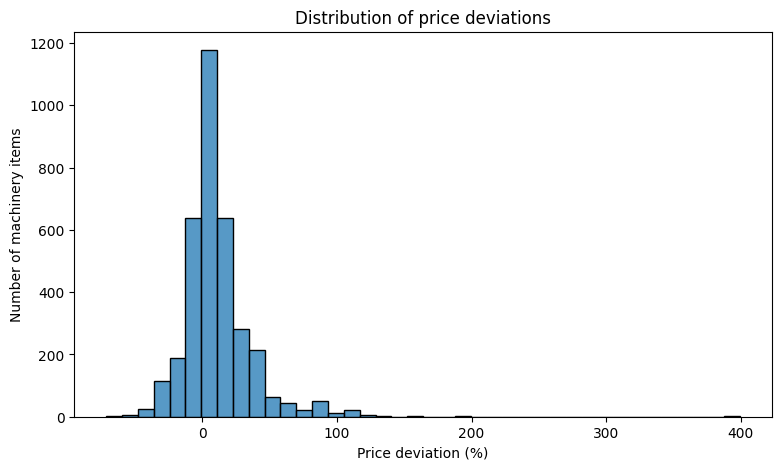

In [44]:
# Distribution of price deviations

plt.figure(figsize=(9, 5))

sns.histplot(data=prices_analysis, x="Price Deviation (%)", bins=40)

plt.title("Distribution of price deviations")
plt.xlabel("Price deviation (%)")
plt.ylabel("Number of machinery items")

plt.show()

Most quoted prices are close to the reference prices, with deviations concentrated around 0%. The distribution is right-skewed, showing that some quoted prices are much higher than their reference prices. These extreme deviations should be investigated further.

I will plot reference prices to understand their distribution.

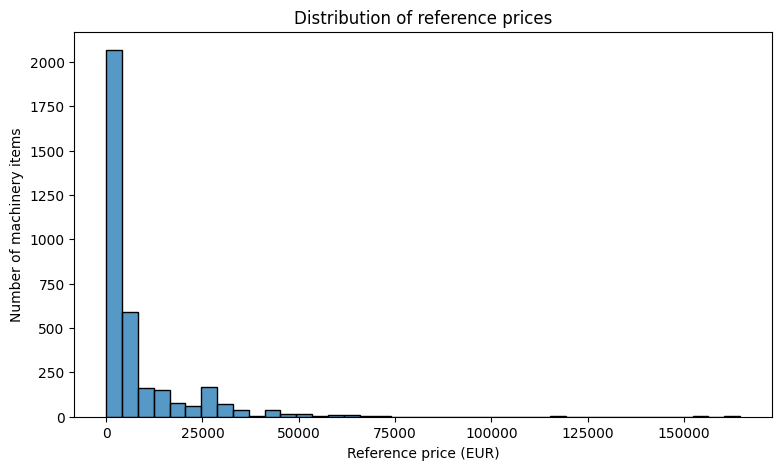

In [45]:
# Distribution of reference prices

plt.figure(figsize=(9, 5))

sns.histplot(
    data=prices_analysis,
    x="Evaluation Committee Reference Price (EUR)", bins=40)

plt.title("Distribution of reference prices")
plt.xlabel("Reference price (EUR)")
plt.ylabel("Number of machinery items")

plt.show()

Most mechanization items have relatively low reference prices, while a smaller number have much higher prices. The distribution is right-skewed, which should be considered when preparing the data for machine learning.

I will plot investment amounts again after excluding the two unverified records.

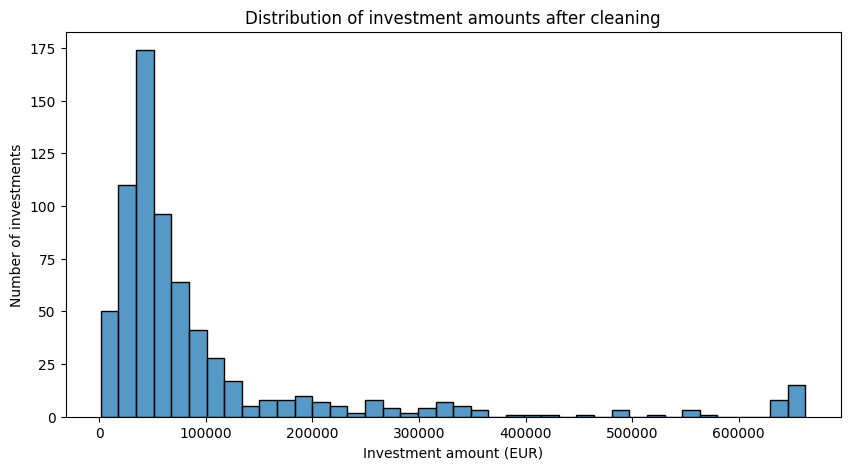

In [46]:
# Investment amount distribution after cleaning

plt.figure(figsize=(10, 5))

sns.histplot(
    data=investments_clean,
    x="Total Requested Investment (Excluding Ineligible Costs) (€)", bins=40)

plt.title("Distribution of investment amounts after cleaning")
plt.xlabel("Investment amount (EUR)")
plt.ylabel("Number of investments")
plt.show()

After excluding the two unverified records, the highest investment amount is 662.629,34 EUR, which is above the public call limit of 650.000 EUR.

Most investments are concentrated between 20.000 and 100.000 EUR.

The distribution is still right-skewed, but the investment amounts are now easier to analyze.

I will calculate descriptive statistics for the cleaned investment amounts.

In [47]:
# Now I want to explore investment amounts to identify two tiers

investment_col = "Total Requested Investment (Excluding Ineligible Costs) (€)"

investments_clean[investment_col].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])

,Total Requested Investment (Excluding Ineligible Costs) (€)
count,693.000000
mean,100540.310945
std,133300.534712
min,1577.440000
25%,35907.210000
50%,52700.000000
75%,94315.000000
90%,235151.390000
95%,369587.104000
max,662629.340000


I will use more histogram bins to examine the distribution in greater detail.

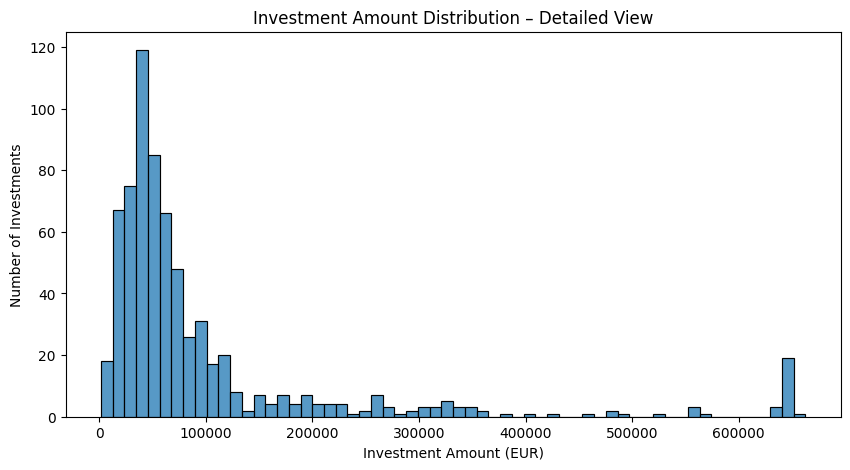

In [48]:
# Exploring the distribution with more detail

plt.figure(figsize=(10, 5))

sns.histplot(
    data=investments_clean,
    x=investment_col,
    bins=60)

plt.title("Investment Amount Distribution – Detailed View")
plt.xlabel("Investment Amount (EUR)")
plt.ylabel("Number of Investments")
plt.show()

I will count investments in different amount ranges to understand the two concentrations.

In [49]:
# Checking investment amounts by range

pd.cut(investments_clean[investment_col],
    bins=[0, 100000, 200000, 300000, 400000, 500000, 600000, 700000]
).value_counts().sort_index()

,count
Total Requested Investment (Excluding Ineligible Costs) (€),
"(0, 100000]",535
"(100000, 200000]",77
"(200000, 300000]",27
"(300000, 400000]",20
"(400000, 500000]",6
"(500000, 600000]",5
"(600000, 700000]",23


I will review the types of investments above 600.000 EUR.

In [50]:
# I want to check investment types above 600,000 EUR

high_investments = investments_clean[
    investments_clean[investment_col] > 600000]

high_investments["Investment Type"].value_counts()

,count
Investment Type,
Purchase of equipment,3
Construction of a building,3
Purchase and installation of a greenhouse,2
Construction,1
Purchase of machinery,1
Construction of a building and purchase of equipment and machinery,1
Construction of a building and purchase of equipment,1
Establishment of plantations,1
Construction and purchase of equipment and vehicles,1


I will create two descriptive investment tiers using 100.000 EUR as a practical threshold.

In [51]:
# Dividing investments into two groups

investments_clean["Investment Tier"] = np.where(
    investments_clean[investment_col] <= 100000,
    "Lower Investments",
    "Higher Investments")

investments_clean["Investment Tier"].value_counts()

,count
Investment Tier,
Lower Investments,535
Higher Investments,158


I will compare the investment amounts in the two groups.

In [52]:
# Now I am comparing investment tiers

investments_clean.groupby("Investment Tier")[investment_col].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Investment Tier,,,,,,,,
Higher Investments,158.0,280357.01,185684.37,101700.00,126556.15,208549.06,343908.18,662629.34
Lower Investments,535.0,47435.57,22296.81,1577.44,31789.00,45140.00,62099.38,99800.00


### Investment tiers – findings

I divided the investments into two groups using 100.000 EUR as a threshold.

**Lower Investments:** This group contains 535 investments (77,2%), with an average amount of 47.435,57 EUR.

**Higher Investments:** This group contains 158 investments (22,8%), with an average amount of 280.357,01 EUR.

The public call defined an investment range from 10.000 to 650.000 EUR, excluding VAT. This may explain the concentration of investment amounts near 650.000 EUR.

The two groups are used to compare lower and higher investment amounts.

## 9. Bivariate exploration

The key relationship is between the farmer’s quoted price and the historical reference price. I will use the calculated deviation to check whether each quote is within ±30% of the reference, then examine the largest differences.

I will classify each record as within or outside ±30% of its reference price.

In [53]:
# Checking if quoted prices are within 30% of reference prices

prices_analysis["Within 30%"] = (
    prices_analysis["Price Deviation (%)"].abs() <= 30)

prices_analysis["Within 30%"].value_counts()

,count
Within 30%,
True,2893
False,612


### Price evaluation – 30% threshold

Out of 3.505 mechanization records, 2.893 (82,5%) have quoted prices within ±30% of the reference price.

The remaining 612 records (17,5%) fall outside this range.

This analysis uses historical reference prices and does not yet represent machine learning predictions.

I will plot the number of records inside and outside the ±30% range.

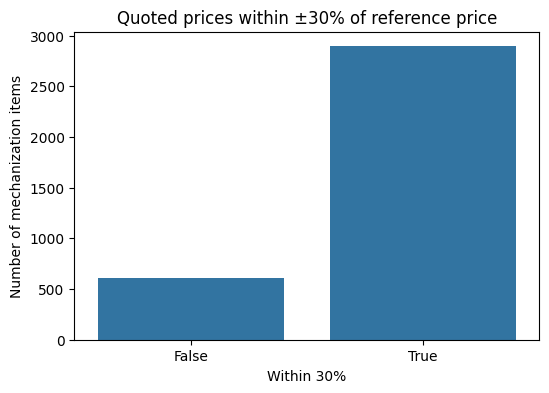

In [54]:
# Visualize the 30% price threshold results

plt.figure(figsize=(6, 4))

sns.countplot(data=prices_analysis, x="Within 30%")

plt.title("Quoted prices within ±30% of reference price")
plt.xlabel("Within 30%")
plt.ylabel("Number of mechanization items")

plt.show()

The chart shows that most quoted mechanization prices (82,5%) are within ±30% of the reference prices.

The remaining 17,5% fall outside this range.

I will review the ten largest positive deviations and their equipment descriptions.

In [55]:
# Now I want to see the 10 highest price deviations

prices_analysis.nlargest(10, "Price Deviation (%)")[
    ["Equipment / Item",
     "Manufacturer / Brand",
     "Model / Specifications",
     "Applicant Quoted Price (EUR)",
     "Evaluation Committee Reference Price (EUR)",
     "Price Deviation (%)"]]

,Equipment / Item,Manufacturer / Brand,Model / Specifications,Applicant Quoted Price (EUR),Evaluation Committee Reference Price (EUR),Price Deviation (%)
2067,Manual milk meter,NaN,30 l,2100.00,420.32,399.619338
2063,Vacuum pump,Melasty,1100 l,6770.00,2273.95,197.719827
2471,Plow,Leopard,L35.3VK three-furrow,5247.93,1776.63,195.386772
3400,Hazelnut vacuum harvester,NaN,3.6 kw,2850.00,1090.98,161.233020
2985,Sprayer,NaN,"AGS 440 l, 10m boom",2863.52,1220.83,134.555180
1835,PTO shaft,NaN,c line 04 DZ,389.22,172.54,125.582474
1543,Plow,Turan,10 inch three-furrow,2100.00,931.41,125.464618
1729,Plow,Turan,10 inch three-furrow,2100.00,931.41,125.464618
1742,Plow,Turan,10 inch three-furrow,2100.00,931.41,125.464618
2558,Plow,Turan,10 inch three-furrow,2100.00,931.41,125.464618


### Highest price deviations

Some mechanization items have quoted prices significantly higher than their reference prices, with the largest deviation reaching almost 400%. These results show why price evaluation is important and support the main research question of this project.

I will also compare quoted prices directly with their corresponding reference prices. Each point represents one mechanization record.

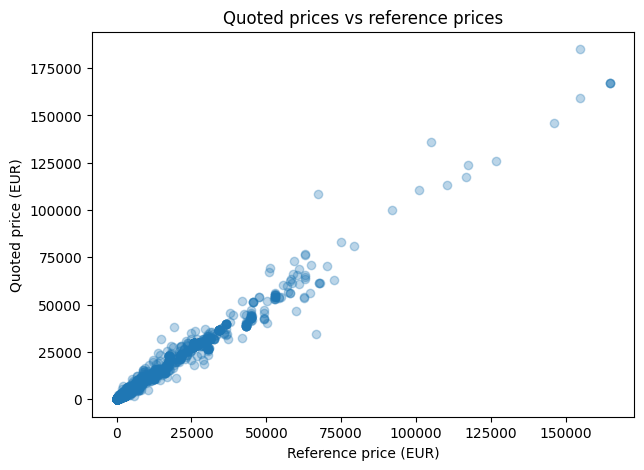

In [56]:
# Compare quoted and reference prices
plt.figure(figsize=(7, 5))
plt.scatter(
    prices_analysis["Evaluation Committee Reference Price (EUR)"],
    prices_analysis["Applicant Quoted Price (EUR)"],
    alpha=0.3)
plt.xlabel("Reference price (EUR)")
plt.ylabel("Quoted price (EUR)")
plt.title("Quoted prices vs reference prices")
plt.show()

This scatter plot shows how quoted prices relate to reference prices. Points farther from an equal-price relationship represent larger absolute differences. Percentage deviation is used for the actual ±30% decision.

## 10. Key findings

- The original price dataset contains **6.622 records**, but many rows lack essential information.
- After filtering and removing **16 exact duplicates**, `prices_clean` contains **3.954 records**. The `Record Frequency` column preserves the frequency of identical rows.
- There are **3.505 records** with both quoted and numeric reference prices.
- **2.893 (82,5%)** quoted prices fall within ±30% of their historical reference prices; **612 (17,5%)** fall outside.
- The investment dataset contains **695 original records**. Two very high, unverified amounts were excluded from the cleaned investment analysis, leaving **693 records**.
- Investments are concentrated at lower values, although a smaller group is much higher. The 100.000 EUR threshold is a practical descriptive division, not a discovered statistical boundary.

## 11. Decisions carried forward

For the Modeling notebook, I will use the clean prices_analysis table, not the investment table. The datasets cannot be reliably merged because a common identifier has not been confirmed. The input variables will describe equipment type, manufacturer, model/specifications and the farmer’s quoted price. The target will be the historical committee reference price. Derived reference-price columns and existing deviation/decision columns will not be used as model inputs, to avoid data leakage.

### Feature selection for modeling

In this section, I will select and prepare relevant features for machine learning. The goal is to use mechanization information to evaluate quoted prices.

I will select the initial model features from the cleaned price records.

In [57]:
# Select relevant features

features = [
    "Equipment / Item",
    "Manufacturer / Brand",
    "Model / Specifications"]

X = prices_analysis[features].copy()

X.head(10)

,Equipment / Item,Manufacturer / Brand,Model / Specifications
0,Potato ridger,Bomet,P475 3 rows
1,Potato planter,Bomet,S239/1 two-row
2,Potato digger,Bomet,Z655 side-mounted
3,Rotary tiller,Farmers,180 cm
4,Hay rake,FPM Deljanin,200 cm belt-type
5,Cab tractor,Lovol,M504
6,Rotary tiller,Farmers,160 cm
7,Trailer with side extensions,Fermak,4t
8,Rotary mower,FPM,DK130/31N disc-type
9,Cab tractor,Lovol,M754


I will check missing values in the selected features.

In [58]:
# Checking missing values in selected features

X.isnull().sum()

,0
Equipment / Item,0
Manufacturer / Brand,518
Model / Specifications,23


I will replace missing manufacturer names and model specifications with "Unknown" while keeping all records for modeling.

In [59]:
# Fill missing text values with "Unknown" because these records
# still contain useful information about the mechanization and its price.


X["Manufacturer / Brand"] = X["Manufacturer / Brand"].fillna("Unknown")
X["Model / Specifications"] = X["Model / Specifications"].fillna("Unknown")

X.isnull().sum()

,0
Equipment / Item,0
Manufacturer / Brand,0
Model / Specifications,0


The Manufacturer / Brand column had 518 missing values, while Model / Specifications had 23 missing values. I replaced both with "Unknown" to keep all records.

All three selected features now have no missing values.

I will identify the historic reference price as the target variable.

In [60]:
# Now I want to define the target variable

y = prices_analysis["Evaluation Committee Reference Price (EUR)"]

y.head(10)

,Evaluation Committee Reference Price (EUR)
0,627.82
1,1427.63
2,1621.54
3,1443.61
4,855.00
5,21549.00
6,1232.21
7,4821.40
8,3313.13
9,25878.50


### Defining the target variable

I selected the Evaluation Committee Reference Price as the target variable (y). The goal is to predict reference prices using equipment type, manufacturer and model specifications, without using farmers' quoted prices as model inputs.

I will count missing model/specification descriptions.

In [61]:
# Checking missing model specifications
prices_analysis["Model / Specifications"].isnull().sum()

np.int64(23)

I will preview model specifications to understand the text values.

In [62]:
# Preview model specifications

prices_analysis[["Equipment / Item", "Model / Specifications"]].head(15)

,Equipment / Item,Model / Specifications
0,Potato ridger,P475 3 rows
1,Potato planter,S239/1 two-row
2,Potato digger,Z655 side-mounted
3,Rotary tiller,180 cm
4,Hay rake,200 cm belt-type
5,Cab tractor,M504
6,Rotary tiller,160 cm
7,Trailer with side extensions,4t
8,Rotary mower,DK130/31N disc-type
9,Cab tractor,M754


I will count unique categories to understand how many distinct values will need encoding.

In [63]:
# Counting unique values in categorical features

X[["Equipment / Item", "Manufacturer / Brand", "Model / Specifications"]].nunique()

,0
Equipment / Item,171
Manufacturer / Brand,208
Model / Specifications,953


### Feature engineering – findings

Three features were selected to predict the reference price: equipment type, manufacturer, and model specifications.

The farmer's quoted price will not be used as a model input. It will be used later to compare with the predicted reference price and evaluate the price deviation.

All missing values in the selected features have been handled.

The categorical features will be transformed during modeling.

## 12. Export

The cleaned dataset is saved as `prices_analysis_clean.csv` and will be used in the next notebook for machine learning modeling.

In [64]:
# Save the cleaned dataset for modeling

prices_analysis.to_csv("prices_analysis_clean.csv", index=False)

## 13. Appendix

The original Excel datasets remain unchanged. The EDA includes data quality checks, cleaning steps, visualizations, and key findings.

The cleaned prices dataset is saved as `prices_analysis_clean.csv` and will be used in `02_Modeling.ipynb`.